In [1]:
import matplotlib.pyplot as plt
import numpy as np
from shapely.plotting import plot_polygon
from geometrychecking import data, geometry, plotting

In [2]:
geometry_name = "test_triggergeom"

In [4]:
arrays = geometry.from_parquet(f'../resources/{geometry_name}')
modules = geometry.from_json(f'../resources/{geometry_name}/geojson')

In [5]:
def module_colors(errorbits):
    color = 'green'
    if data.check_error(errorbits, data.errortypes.InvalidTCInModule): color = 'darkorange'
    if data.check_error(errorbits, data.errortypes.MissingTCInModule): color = 'red'
    return color

## CE-E
### Module issues
Pictures of CE-E layers below show:

- Grey: disconnected modules
- Green: connected modules without any issue detected
- Orange: modules from which invalid trigger cells are retrieved
- Red: modules from which there are missing trigger cells. Missing trigger cells are shown as red dots

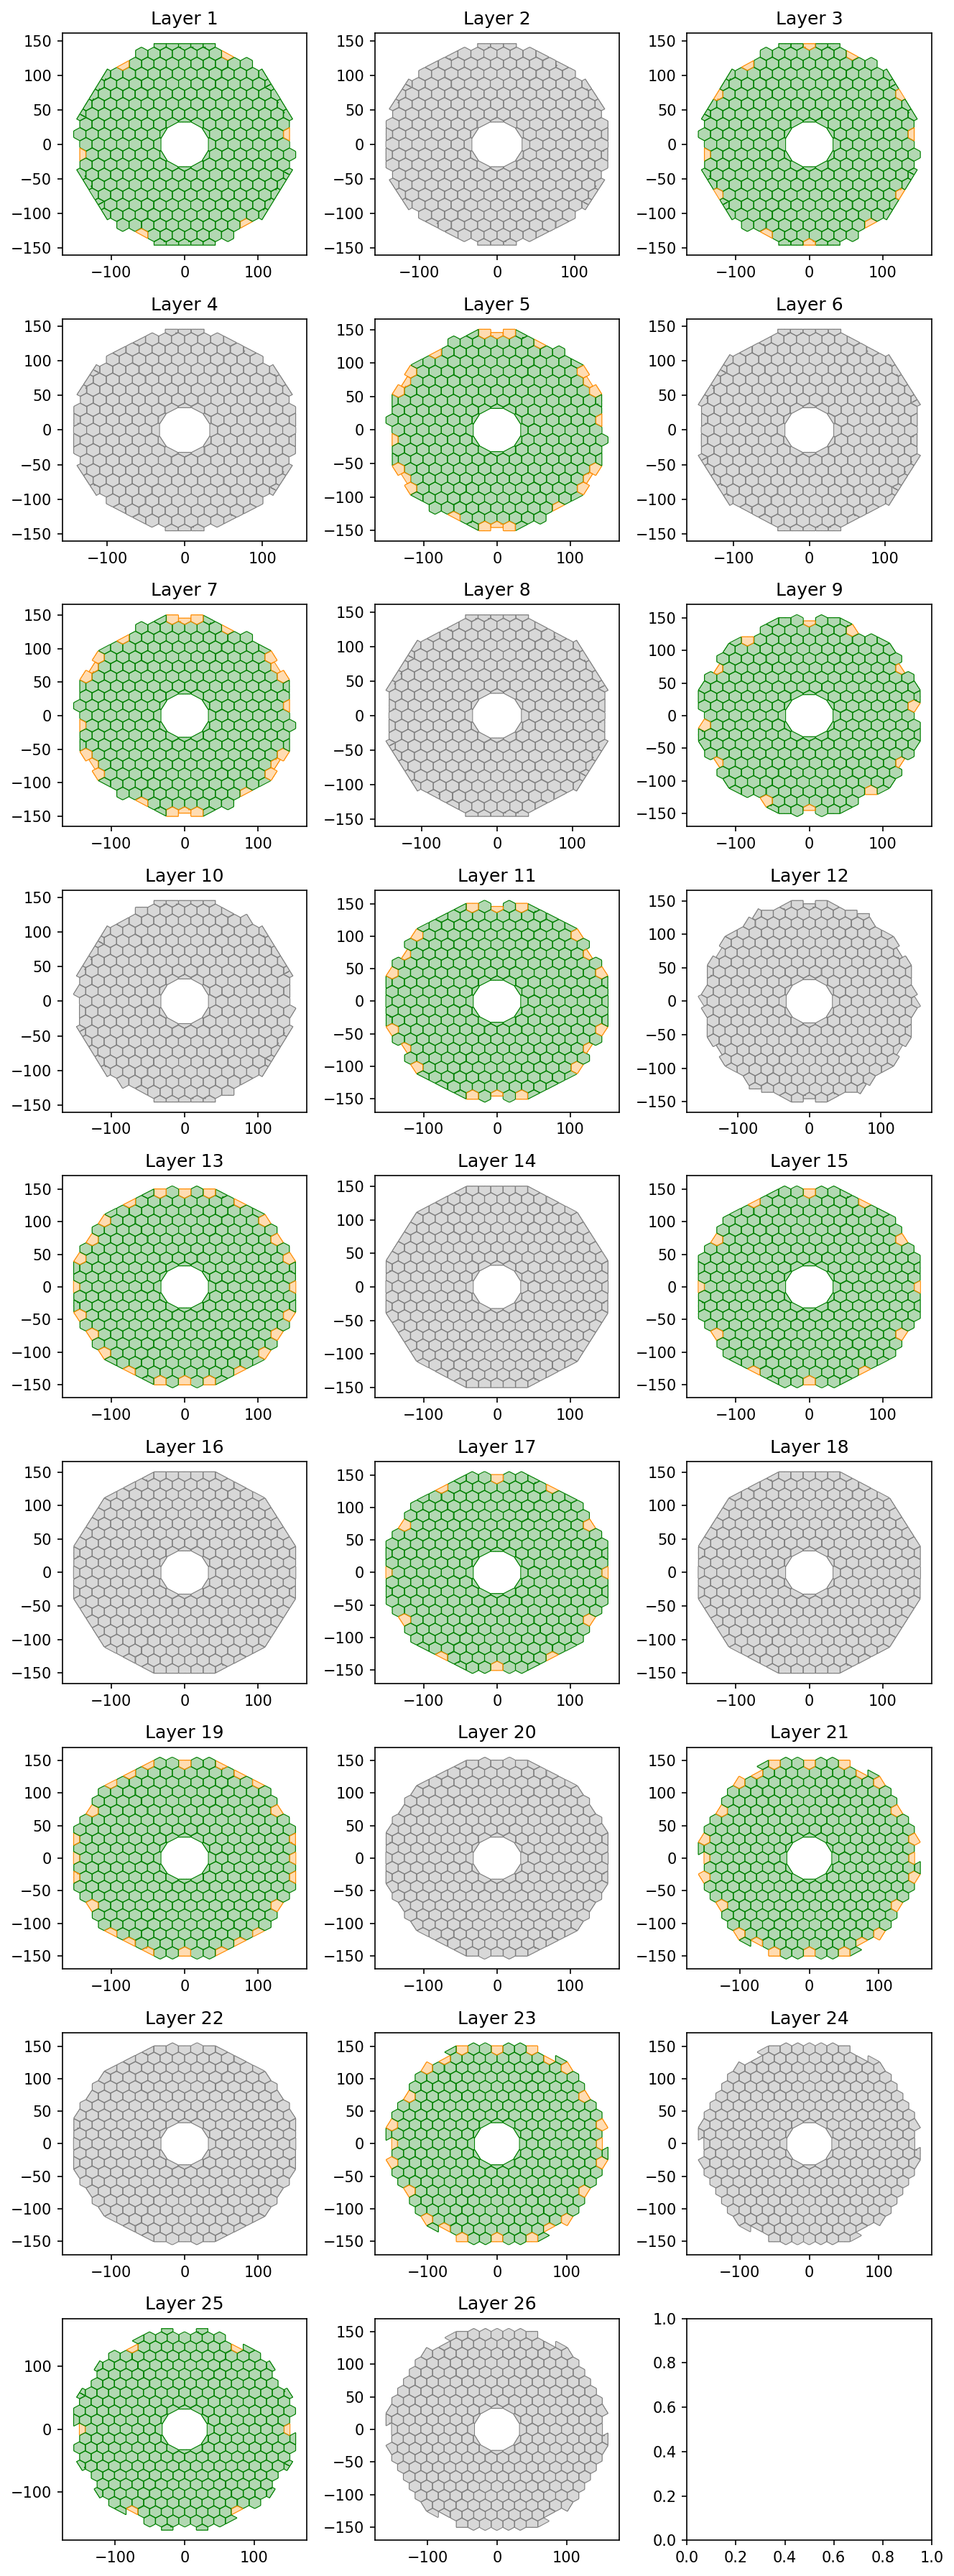

In [6]:
fig, axes = plt.subplots(nrows=9, ncols=3, figsize=(9, 24), dpi=150)
for layer,mods in modules['cee'].items():
    tcs = arrays['cee'][layer]['triggercells']
    modules_arr = arrays['cee'][layer]['modules']
    error_tcs = tcs[tcs.errorbits>0]
    ax = axes[(layer-1)//3, (layer-1)%3]
    for module in mods:
        modid = module['modid']
        mod_poly = module['shape']
        errorbits = module['errors']
        disconnected = module['disconnected']
        color = module_colors(errorbits)
        if disconnected: color = 'grey'
        buffer = mod_poly.length/1000
        plot_polygon(mod_poly.buffer(buffer).buffer(-buffer), ax=ax, color=color, add_points=False, linewidth=0.5)
        #tcs_in_module = tcs[np.isin(tcs.id, modules_arr[modules_arr.id==modid].triggercells[0])]
        mod_tcs = tcs[tcs.modid==modid]
        tcs_notin_module = mod_tcs[np.isin(mod_tcs.id, modules_arr[modules_arr.id==modid].triggercells[0], invert=True)]
        #if(data.check_error(errorbits, data.errortypes.MissingTCInModule)):
        #    ax.scatter(tcs_in_module.x, tcs_in_module.y, s=4, color='darkred')
        if(data.check_error(errorbits, data.errortypes.MissingTCInModule)):
            ax.scatter(tcs_notin_module.x, tcs_notin_module.y, s=2, color='darkred', marker='.', linewidth=0)
    #ax.scatter(error_tcs.x, error_tcs.y, s=4, color='darkred')
    ax.set_title(f"Layer {layer}")
plt.tight_layout()
plt.show()

### Trigger cells issues
Pictures of CE-E layers below show:

- Red dots: trigger cells containing invalid cells
- Pink dots: trigger cells in which some cells are missing

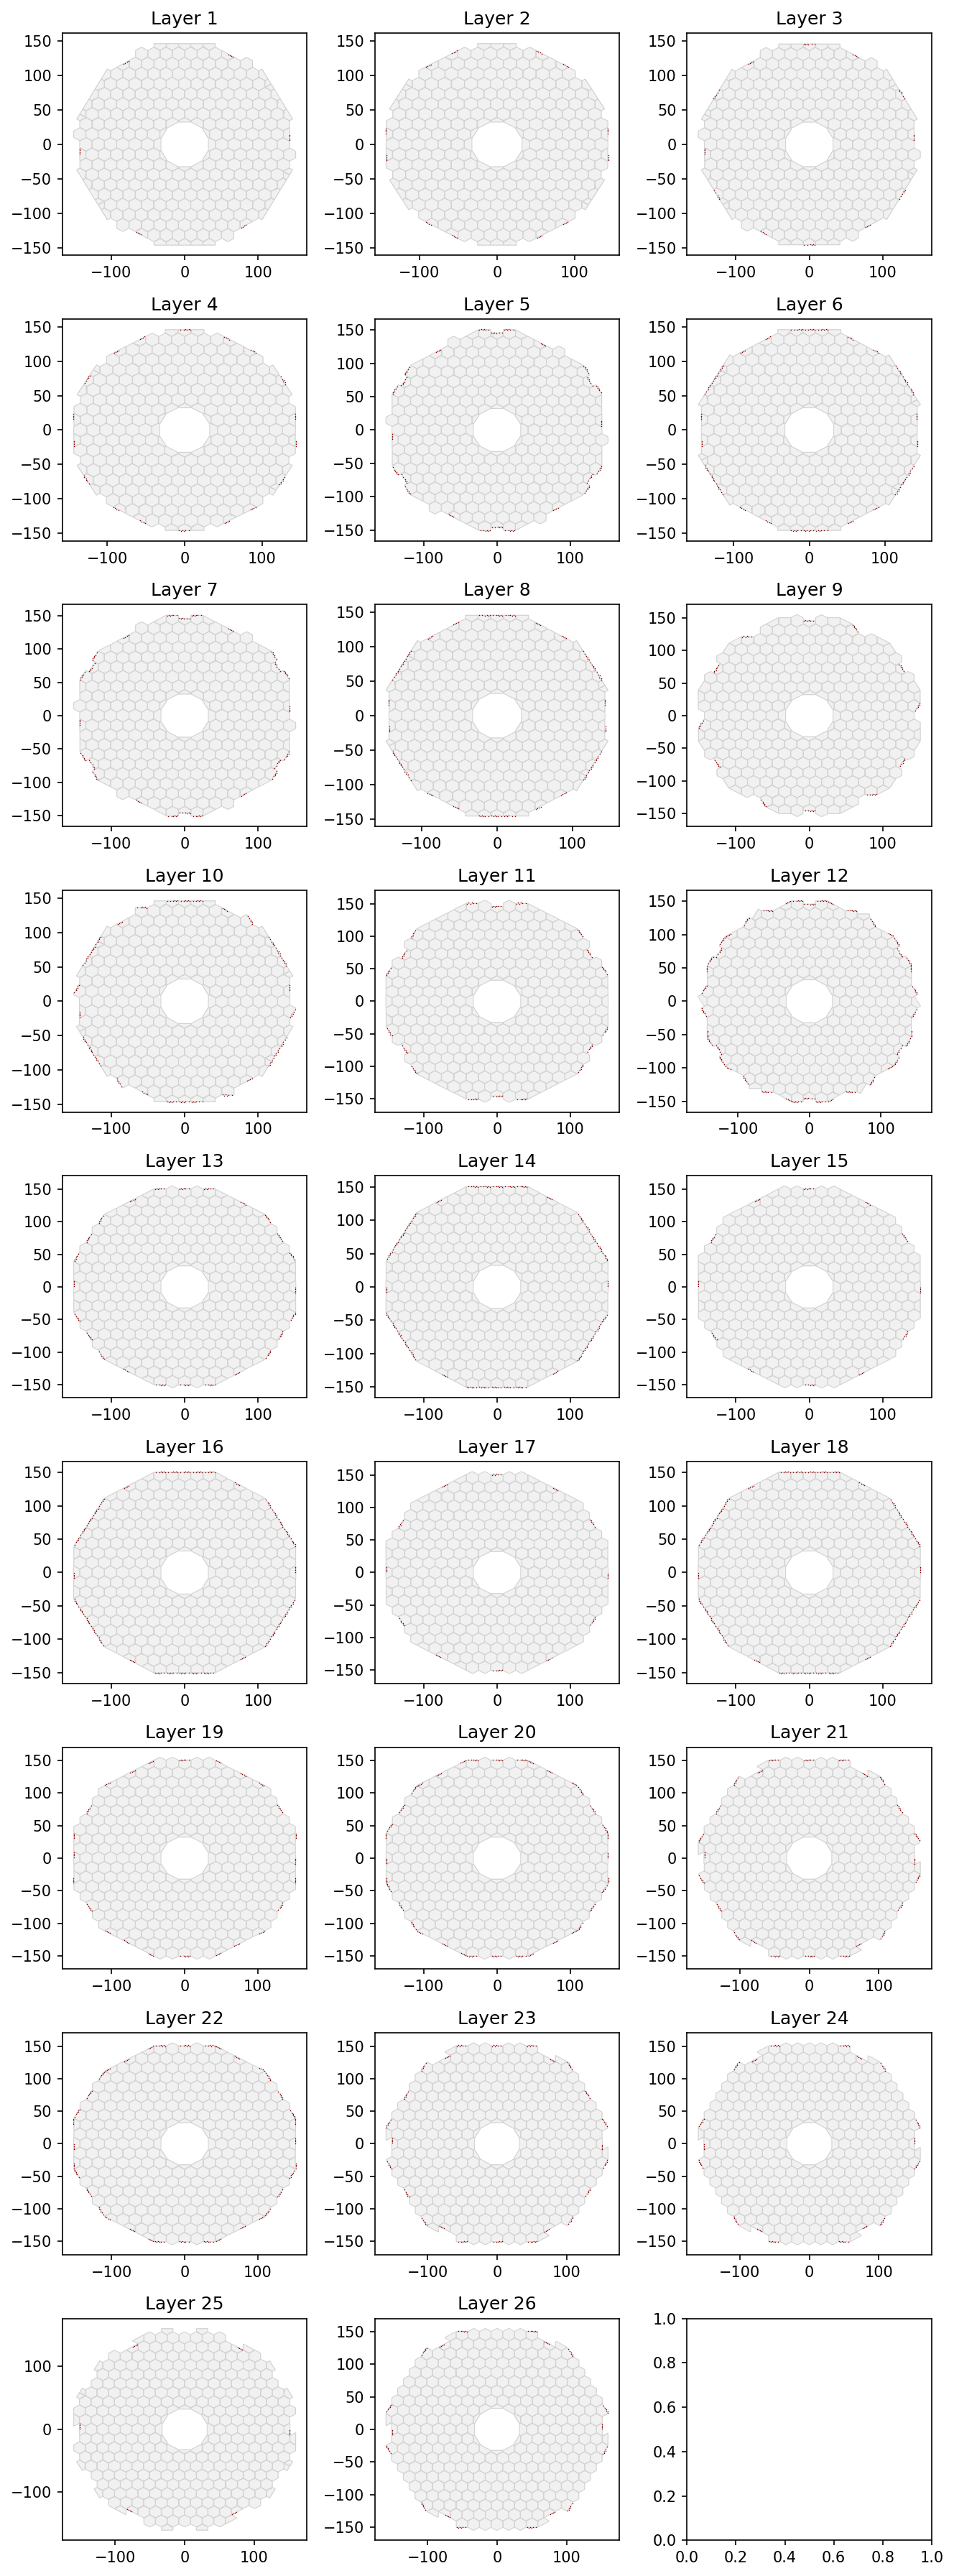

In [7]:
fig, axes = plt.subplots(nrows=9, ncols=3, figsize=(9, 24), dpi=150)
for layer,mods in modules['cee'].items():
    tcs = arrays['cee'][layer]['triggercells']
    error_tcs_invalid = data.select_error(tcs, data.errortypes.InvalidCellInTC)
    error_tcs_missing = data.select_error(tcs, data.errortypes.MissingCellInTC)
    ax = axes[(layer-1)//3, (layer-1)%3]
    for module in mods:
        modid = module['modid']
        mod_poly = module['shape']
        errorbits = module['errors']
        disconnected = module['disconnected']
        buffer = mod_poly.length/1000
        plot_polygon(mod_poly.buffer(buffer).buffer(-buffer), ax=ax, color='lightgrey', add_points=False, linewidth=0.5)
    ax.scatter(error_tcs_invalid.x, error_tcs_invalid.y, s=2, color='darkred', marker='.', linewidth=0)
    ax.scatter(error_tcs_missing.x, error_tcs_missing.y, s=2, color='fuchsia', marker='.', linewidth=0)
    ax.set_title(f"Layer {layer}")
plt.tight_layout()
plt.show()

## CE-H
### Module issues
Pictures of CE-H layers below show:

- Grey: disconnected modules
- Green: connected modules without any issue detected
- Orange: modules from which invalid trigger cells are retrieved
- Red: modules from which there are missing trigger cells. Missing trigger cells are shown as red dots

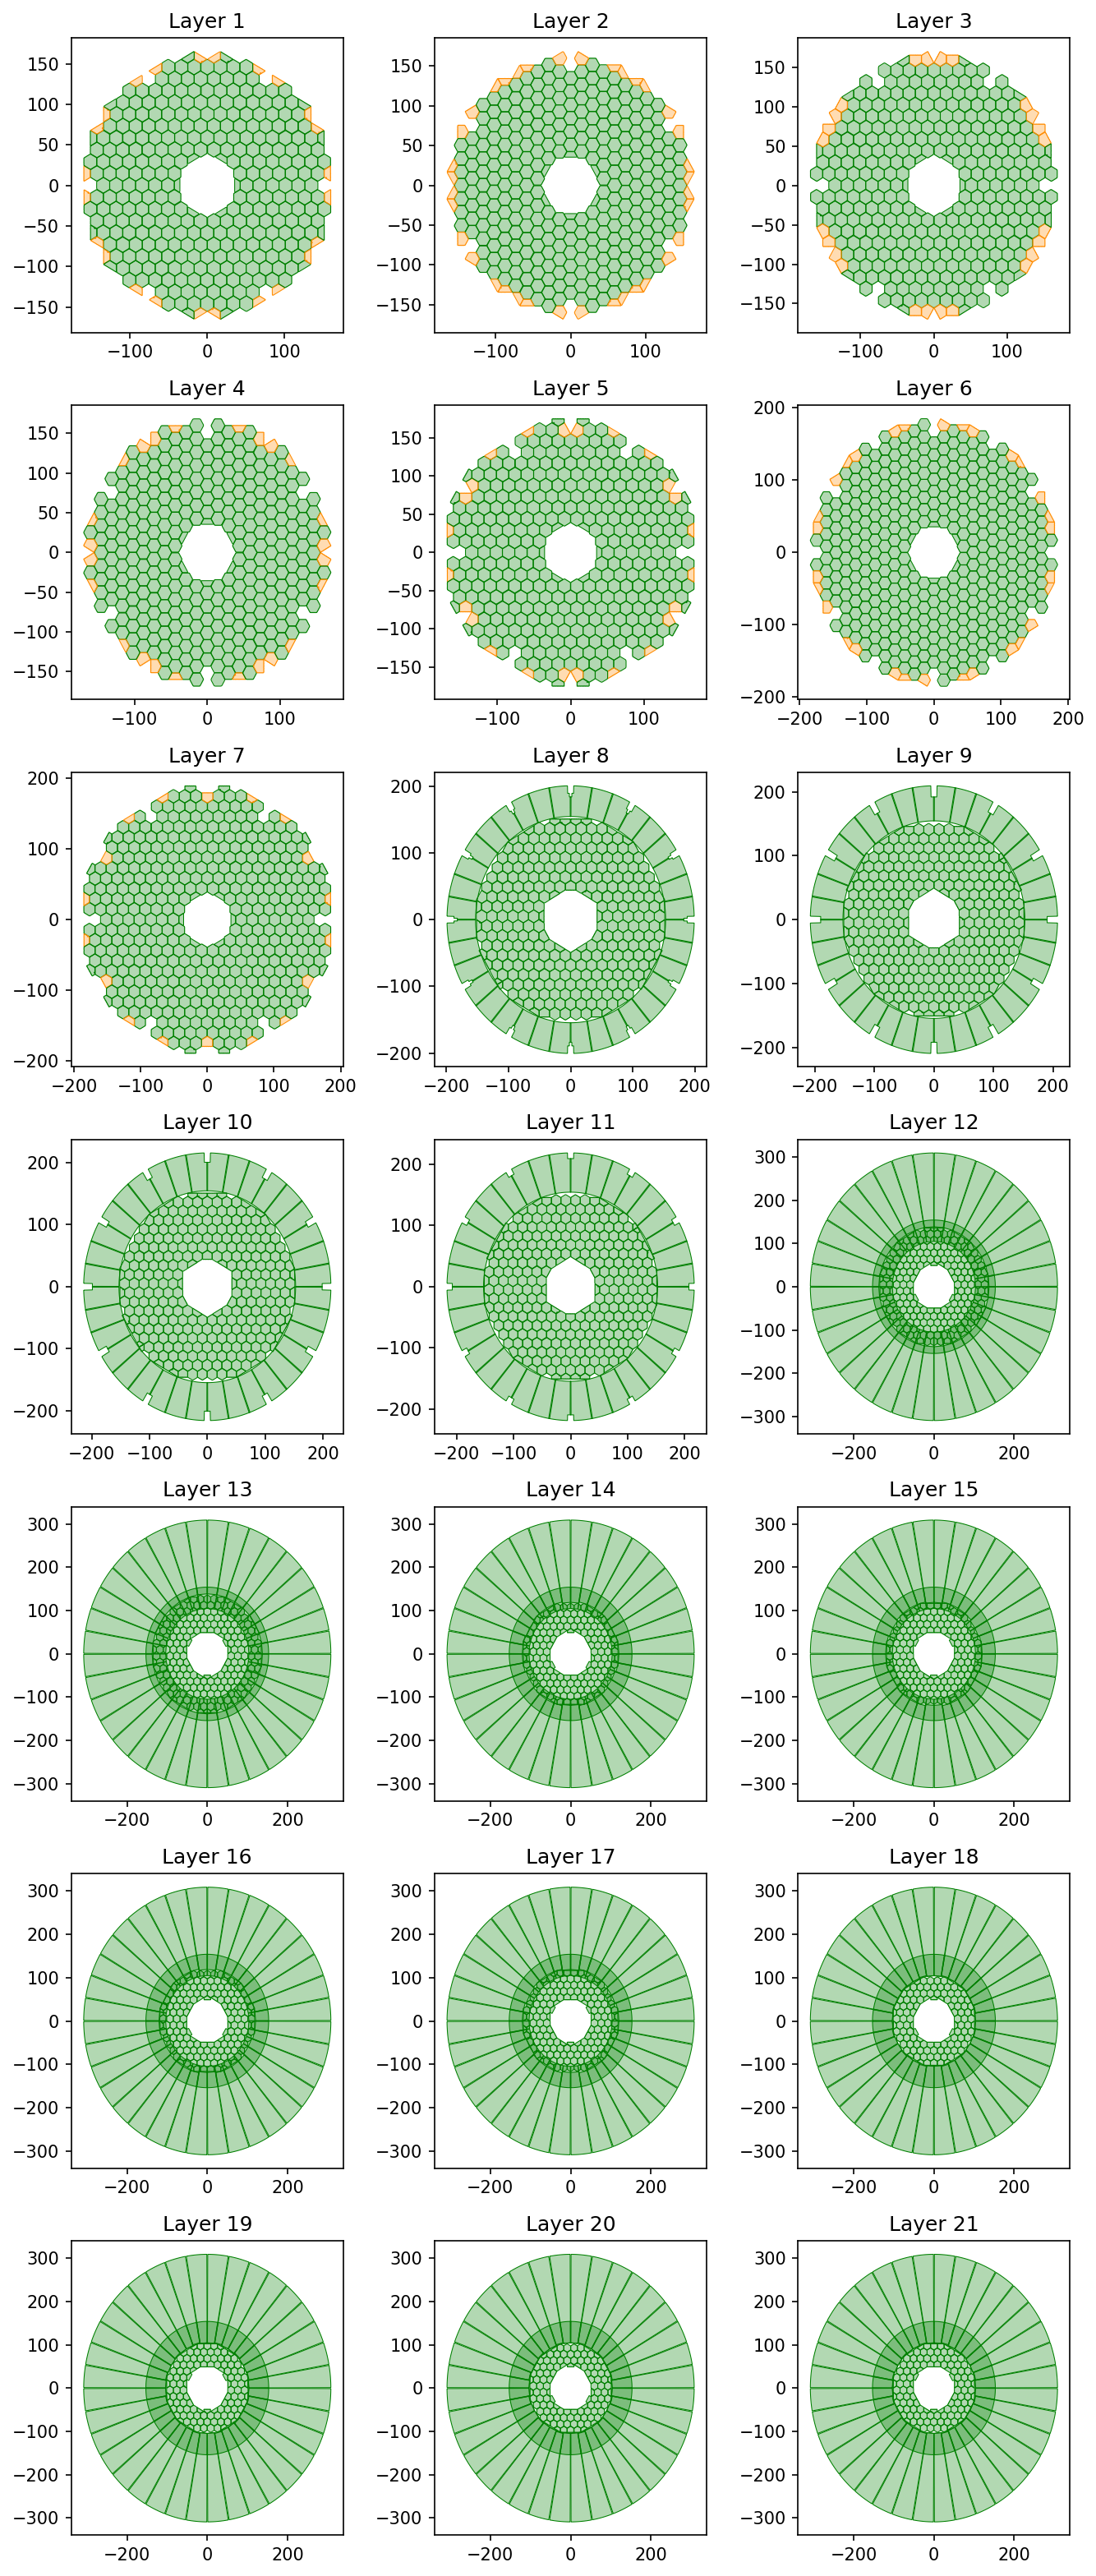

In [8]:
fig, axes = plt.subplots(nrows=7, ncols=3, figsize=(9, 21), dpi=150)
for layer,mods in modules['ceh'].items():
    tcs = arrays['ceh'][layer]['triggercells']
    modules_arr = arrays['ceh'][layer]['modules']
    #error_tcs = data.select_error(tcs, data.errortypes.InvalidCellInTC)
    ax = axes[(layer-1)//3, (layer-1)%3]
    for module in mods:
        modtype = module['type']
        modid = module['modid']
        mod_poly = module['shape']
        errorbits = module['errors']
        disconnected = module['disconnected']
        color = module_colors(errorbits)
        if disconnected: color = 'grey'
        if modid==1858831025: color='blueviolet'
        buffer = mod_poly.length/1000
        plot_polygon(mod_poly.buffer(buffer).buffer(-buffer), ax=ax, color=color, add_points=False, linewidth=0.5)
        #tcs_in_module = tcs[np.isin(tcs.id, modules_arr[modules_arr.id==modid].triggercells[0])]
        mod_tcs = tcs[tcs.modid==modid]
        tcs_notin_module = mod_tcs[np.isin(mod_tcs.id, modules_arr[modules_arr.id==modid].triggercells[0], invert=True)]
        #if(data.check_error(errorbits, data.errortypes.MissingTCInModule)):
        #    ax.scatter(tcs_in_module.x, tcs_in_module.y, s=4, color='darkred')
        if(data.check_error(errorbits, data.errortypes.MissingTCInModule)):
            ax.scatter(tcs_notin_module.x, tcs_notin_module.y, s=2, color='darkred', marker='.', linewidth=0)
        
    #ax.scatter(error_tcs.x, error_tcs.y, s=4, color='darkred')
    ax.set_title(f"Layer {layer}")
plt.tight_layout()
plt.show()

### Trigger cells issues
Pictures of CE-H layers below show:

- Red dots: trigger cells containing invalid cells
- Pink dots: trigger cells in which some cells are missing

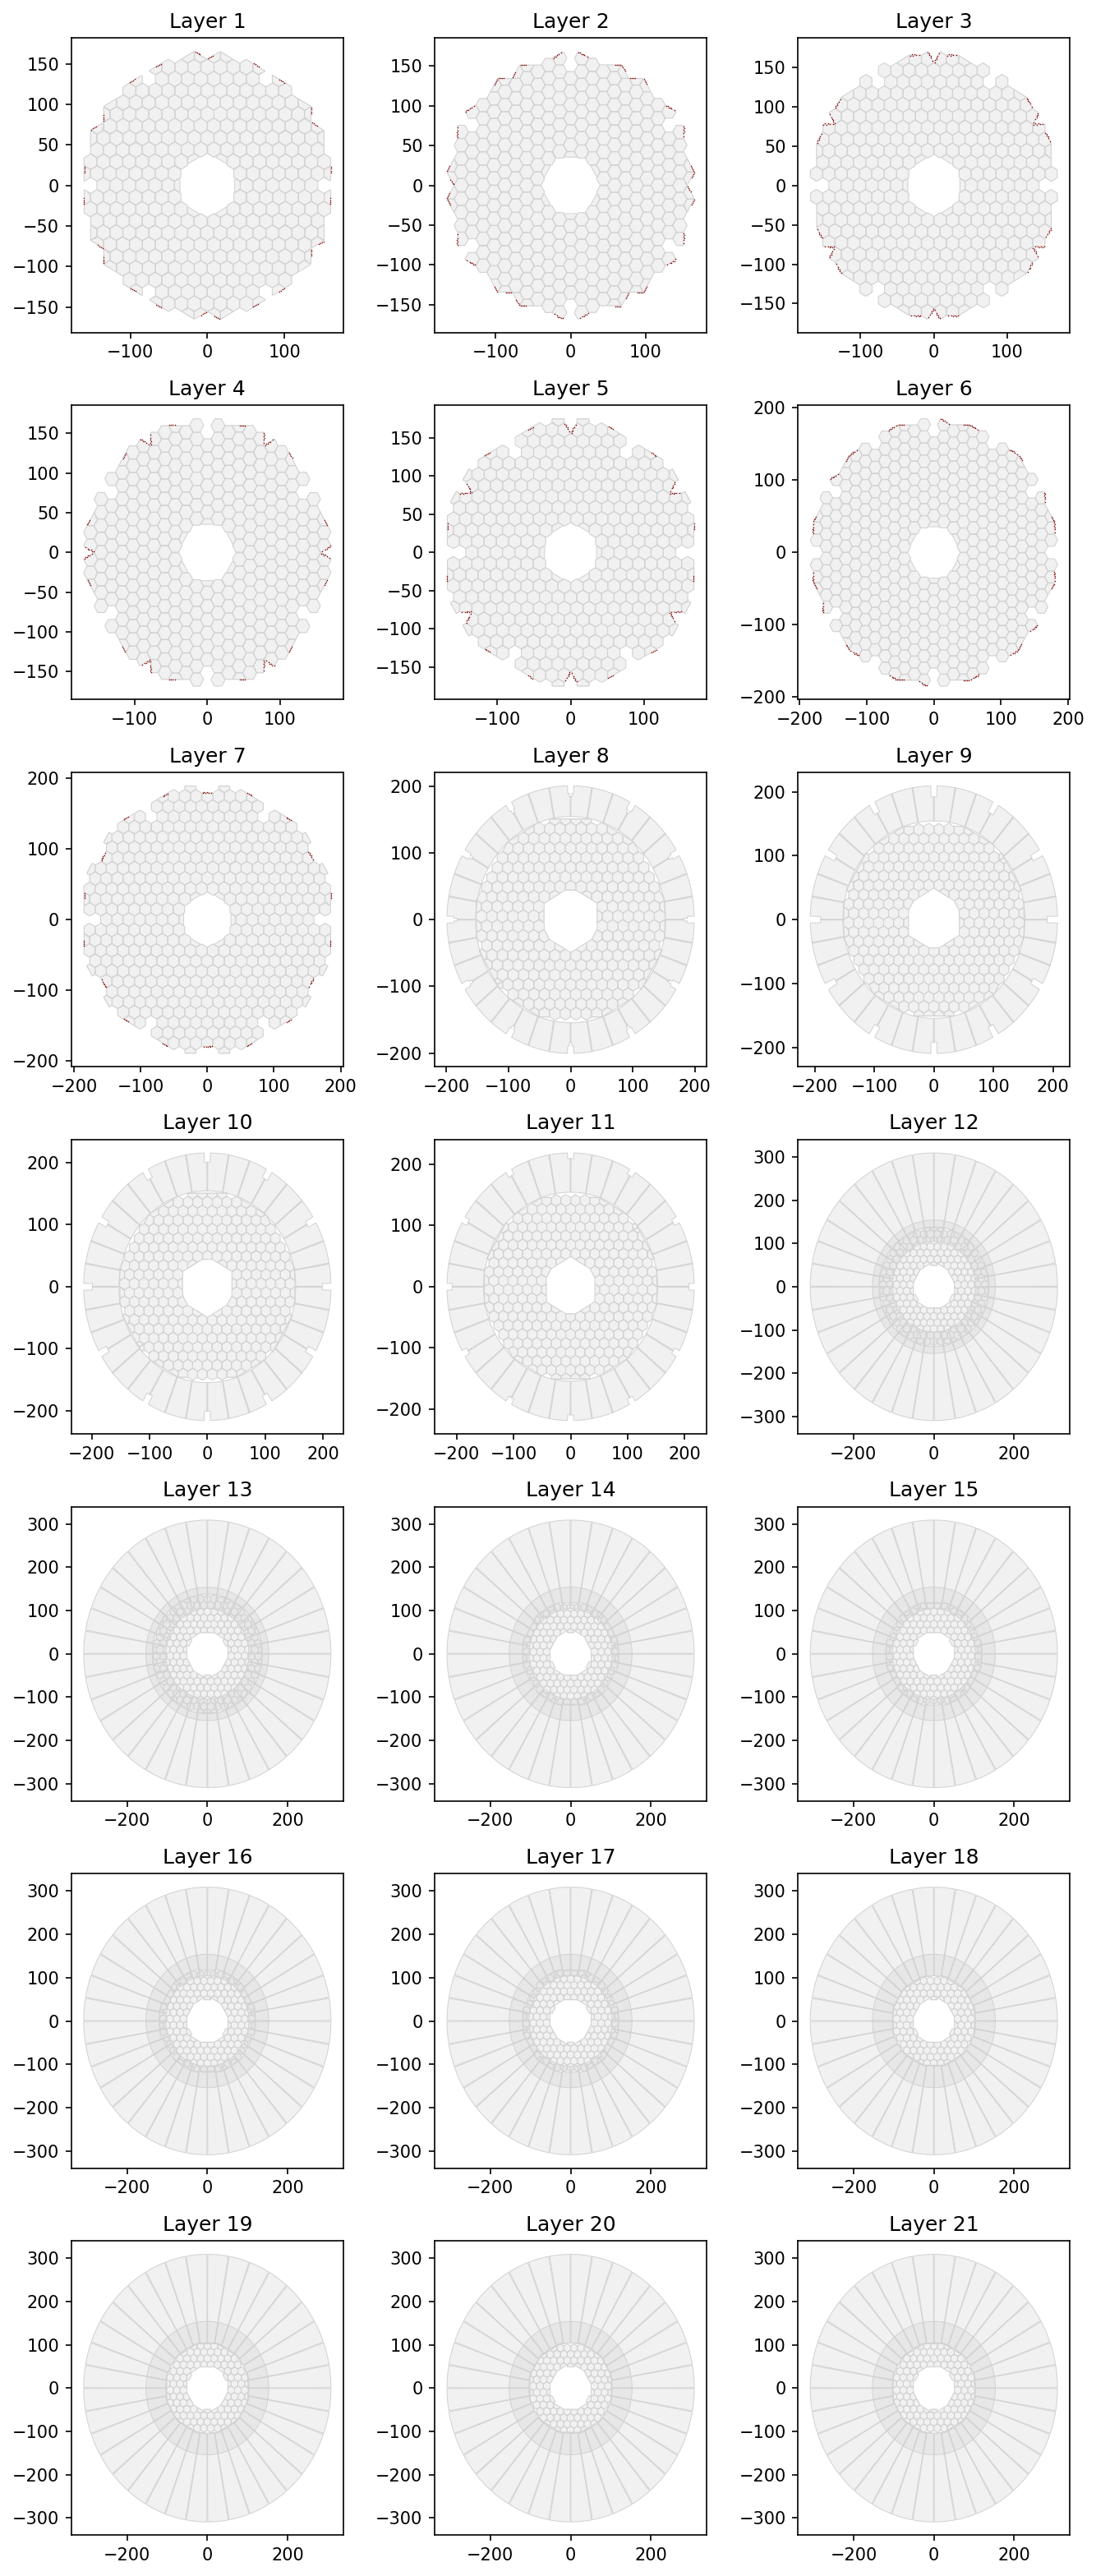

In [9]:
fig, axes = plt.subplots(nrows=7, ncols=3, figsize=(9, 21), dpi=150)
for layer,mods in modules['ceh'].items():
    tcs = arrays['ceh'][layer]['triggercells']
    error_tcs_invalid = data.select_error(tcs, data.errortypes.InvalidCellInTC)
    error_tcs_missing = data.select_error(tcs, data.errortypes.MissingCellInTC)
    ax = axes[(layer-1)//3, (layer-1)%3]
    for module in mods:
        modid = module['modid']
        mod_poly = module['shape']
        errorbits = module['errors']
        disconnected = module['disconnected']
        buffer = mod_poly.length/1000
        plot_polygon(mod_poly.buffer(buffer).buffer(-buffer), ax=ax, color='lightgrey', add_points=False, linewidth=0.5)
    ax.scatter(error_tcs_invalid.x, error_tcs_invalid.y, s=2, color='darkred', marker='.', linewidth=0)
    ax.scatter(error_tcs_missing.x, error_tcs_missing.y, s=2, color='fuchsia', marker='.', linewidth=0)
    ax.set_title(f"Layer {layer}")
plt.tight_layout()
plt.show()